# Analysis of iPSC dataset

We use the iPSC reprogramming dataset by [Schiebinger et al. 2019](https://doi.org/10.1016/j.cell.2019.01.006), obtained from the [WOT tutorial](https://broadinstitute.github.io/wot/tutorial/). We first have a look at the general suitability of the dataset. The aim is to use a subset of genes that are described in the paper as transcription factors influencing the various fate decisions.

In [1]:
import networkx as nx
import palantir
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.sparse import csr_matrix

In [2]:
# Load the data
obs = pd.read_csv("../data/ipscs/cell_days.txt", sep="\t", header=0, index_col=0)
batches = pd.read_csv(
    "../data/ipscs/batches.txt", sep="\t", header=0, index_col=0
).rename(columns={"covariate": "batch"})
cell_sets = {}
with open("../data/ipscs/major_cell_sets.gmt", "r") as file:
    for line in file:
        name, cells = line.split("\t-\t")
        cell_sets[name] = pd.Series(cells.split())
fle_coords = pd.read_csv("../data/ipscs/fle_coords.txt", sep="\t", index_col=0)
cell_ids_2i = pd.read_csv("../data/ipscs/2i_cell_ids.txt", header=None)[0]
cell_ids_serum = pd.read_csv("../data/ipscs/serum_cell_ids.txt", header=None)[0]
adata = sc.read_h5ad("../data/ipscs/ExprMatrix.h5ad")
assert isinstance(adata.obs, pd.DataFrame)
adata.obs = adata.obs.merge(obs, left_index=True, right_index=True, how="left").merge(
    batches, left_index=True, right_index=True, how="left"
)
adata.obs["serum_cell"] = adata.obs_names.isin(cell_ids_serum)
adata.obs["2i_cell"] = adata.obs_names.isin(cell_ids_2i)
adata.obs["cell_set"] = "MEF"
for name, cell_list in cell_sets.items():
    adata.obs.loc[adata.obs_names.isin(cell_list), "cell_set"] = name
adata.obsm["X_fle"] = fle_coords.loc[adata.obs_names, ["x", "y"]].values

# Drop cells w/o time point annotation and subset to serum condition
adata = adata[~adata.obs["day"].isna() & adata.obs["serum_cell"]].copy()
assert isinstance(adata.obs, pd.DataFrame)
adata.obs.drop(columns=["serum_cell", "2i_cell"], inplace=True)
display(adata)
display(adata.obs)

AnnData object with n_obs × n_vars = 165892 × 19089
    obs: 'day', 'batch', 'cell_set'
    var: 'highly_variable'
    obsm: 'X_fle'
    layers: None (.X)

,day,batch,cell_set
index,,,
D0_Dox_C1_AAACCTGAGTATCTCG-1,0.0,1,MEF
D0_Dox_C1_AAACCTGCAAGCGAGT-1,0.0,1,MEF
D0_Dox_C1_AAACCTGGTCTCTTAT-1,0.0,1,MEF
D0_Dox_C1_AAACCTGTCAACACTG-1,0.0,1,MEF
D0_Dox_C1_AAACCTGTCGTTGCCT-1,0.0,1,MEF
...,...,...,...
D18_serum_C2_TTTGGTTTCTTATCTG-1,18.0,2,Stromal
D18_serum_C2_TTTGTCAAGATTACCC-1,18.0,2,Neural
D18_serum_C2_TTTGTCAAGTGAACAT-1,18.0,2,Epithelial


In [3]:
# Preprocessing (expression matrix is log1p counts per 10k)
adata.layers["log1p"] = adata.X.copy()  # type: ignore
sc.pp.scale(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_neighbors=30)

/mnt/lustre/groups/claassen/clasc316/.conda/envs/palantir/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [4]:
# MAGIC imputation
_ = palantir.utils.run_diffusion_maps(adata, n_components=10, knn=200)
_ = palantir.utils.determine_multiscale_space(adata)
_ = palantir.utils.run_magic_imputation(adata, expression_key="log1p")

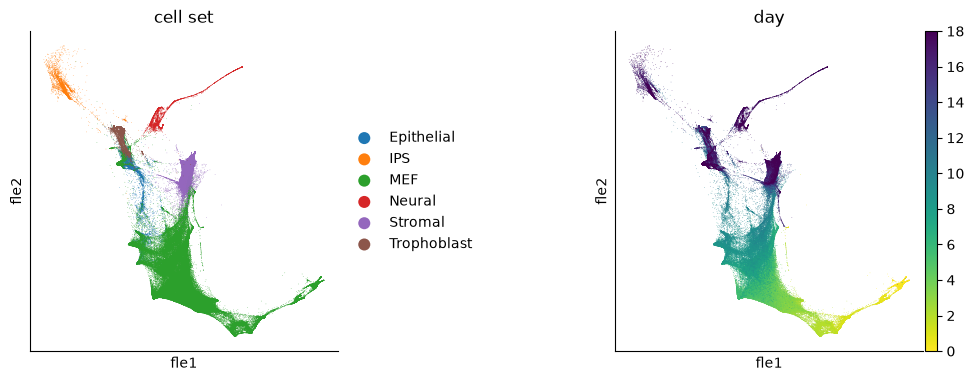

In [5]:
sc.pl.scatter(
    adata, basis="fle", color=["cell_set", "day"], color_map="viridis_r", right_margin=0.9
)

In [6]:
# Annotate relevant genes/TFs for iPSC reprogramming
reprogramming_genes = {
    "MET": ["Dmrtc2", "Pou3f1", "Zic3"],
    "stromal": [
        "Id3", "Nfix", "Nfic", "Prrx1", "Gdf9", "Clcf1", "Crlf1", "Csf1"
    ],
    "epithelial": ["Gata3", "Elf5", "Ovol2", "Ascl2"],
    "trophoblast": ["Csf1r", "Hand1", "Gcm1", "Msx2"],
    "neural": ["Neurod4", "Tal2", "Scrt2", "Cntfr"],
    "iPSC":["Hesx1", "Msc", "Mybl2", "Nanog", "Obox6", "Tdgf1"]
}
reprogramming_genes_data = {}
all_genes = []
for key, lst in reprogramming_genes.items():
    lst_data = []
    for gene in lst:
        if gene in adata.var_names:
            lst_data.append(gene)
            all_genes.append(gene)
        else:
            print(f"Gene {gene} not in adata.")
    reprogramming_genes_data[key] = lst_data
    adata.var[f"{key}_gene"] = adata.var_names.isin(lst)
all_genes = set(all_genes)
adata.var["reprogramming_gene"] = adata.var_names.isin(all_genes)

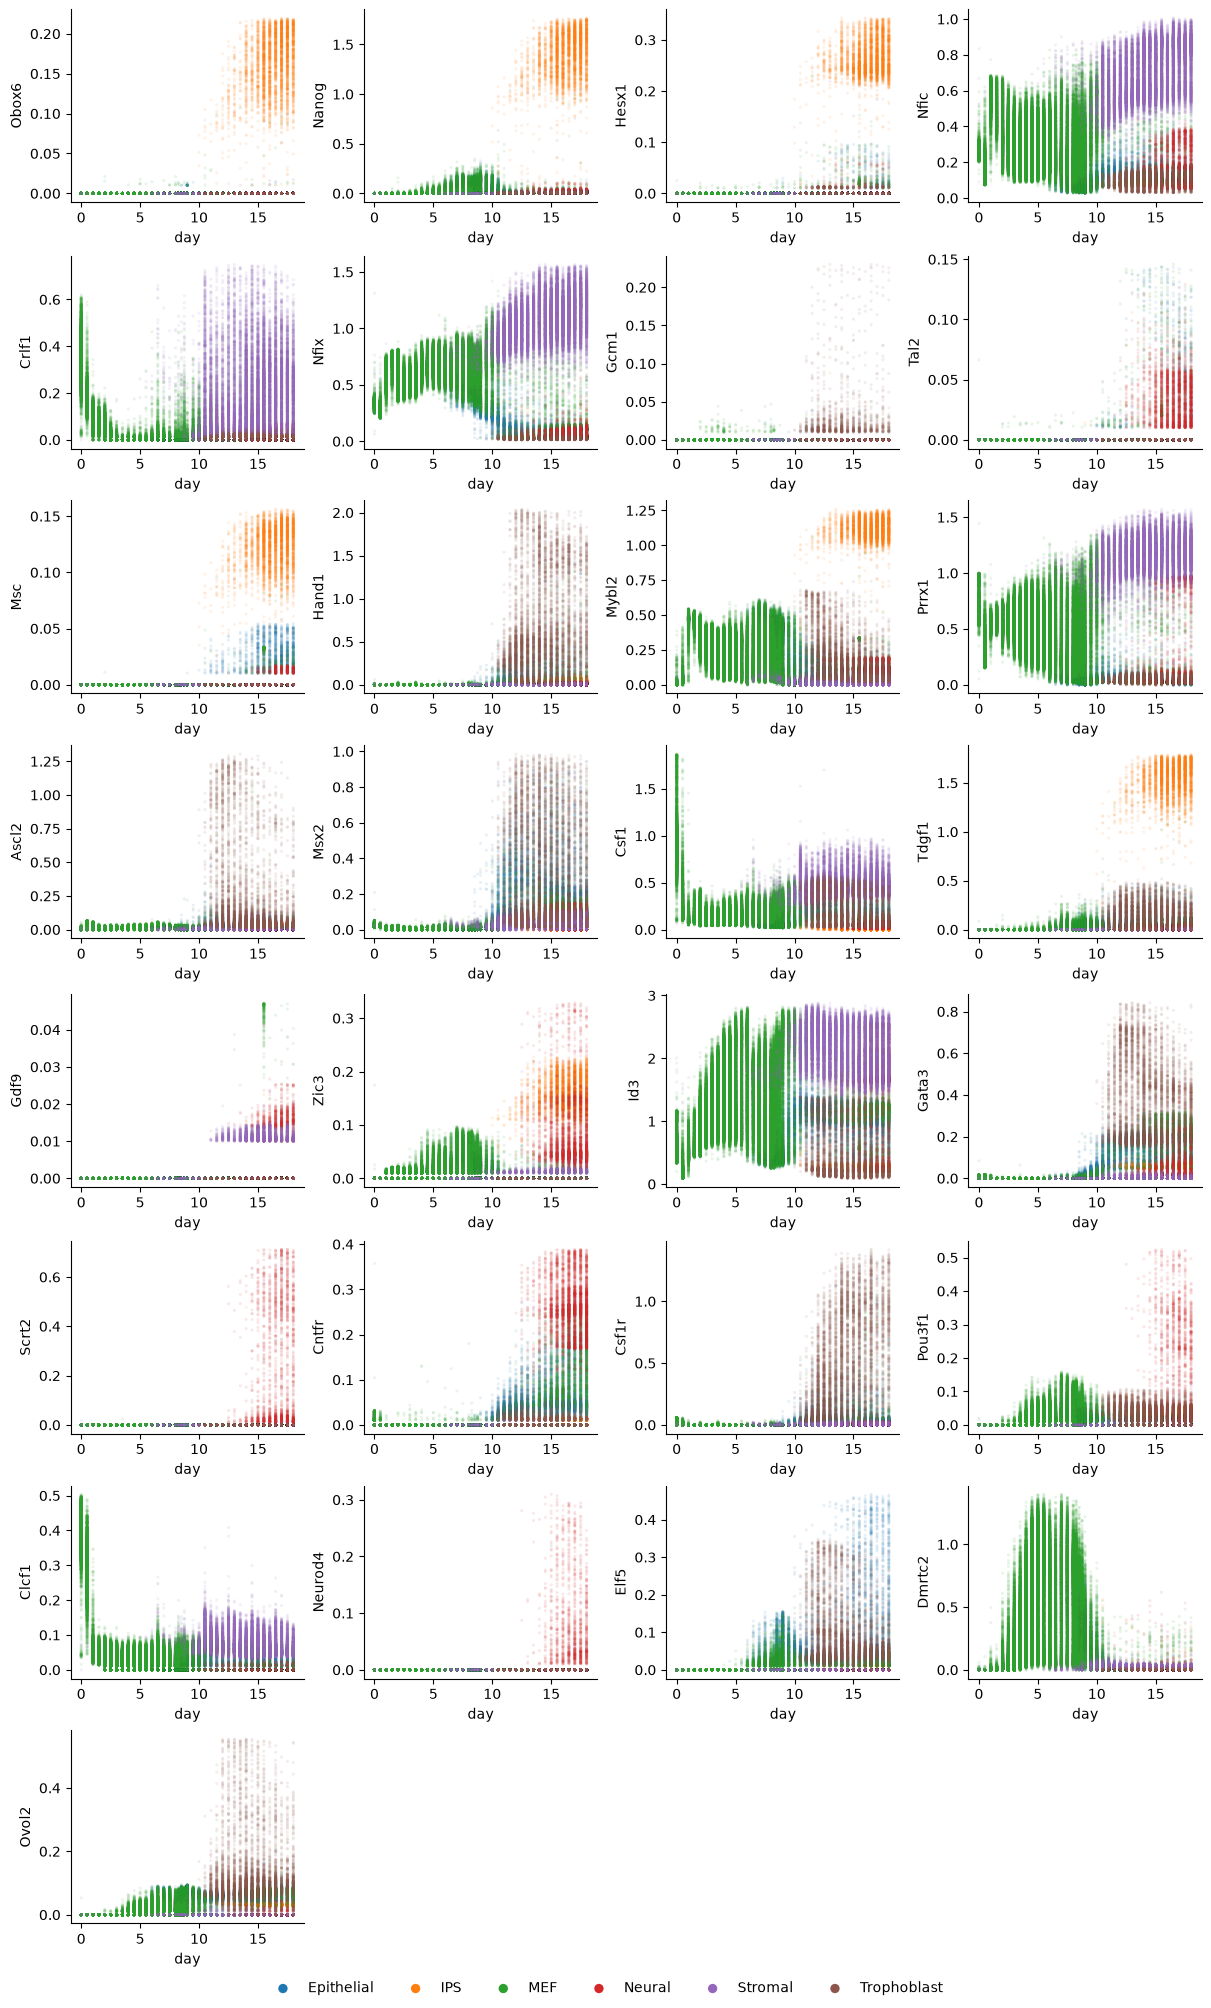

In [7]:
ncol = 4
nrow = int(np.ceil(len(all_genes) / ncol))
fig, axs = plt.subplots(
    nrow, ncol, figsize=(ncol * 3, nrow * 2.5), layout="constrained"
)

for i, gene in enumerate(all_genes):
    sc.pl.scatter(
        adata,
        x="day",
        y=gene,
        layers="MAGIC_imputed_data",
        ax=axs.flat[i],
        color="cell_set",
        size=20,
        show=False,
        title="",
        use_raw=False,
        alpha=0.1,
    )
    axs.flat[i].get_legend().remove()
for ax in axs.flat[len(all_genes) :]:
    ax.set_axis_off()
handles, labels = axs.flat[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels, loc="outside lower center", ncol=8, frameon=False, markerscale=3
)
for lh in legend.legend_handles:
    lh.set_alpha(1)
sns.despine(fig)

In [8]:
# Filter to only highly variable genes, making sure that all
#  reprogramming genes are retained
adata = adata[:, (adata.var["highly_variable"] | (adata.var["reprogramming_gene"]))].copy()

In [9]:
adata.write_h5ad("../data/ipscs_processed_smoothed.h5ad", compression="gzip")